# Decison Trees

First we'll load some fake data on past hires. Note how we use pandas to convert a csv file into a DataFrame:

In [1]:
import numpy as np
import pandas as pd
from sklearn import tree

input_file = "PastHires.csv"
df = pd.read_csv(input_file, header = 0)

In [2]:
df.head()

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
0,10,Y,4,BS,N,N,Y
1,0,N,0,BS,Y,Y,Y
2,7,N,6,BS,N,N,N
3,2,Y,1,MS,Y,N,Y
4,20,N,2,PhD,Y,N,N


scikit-learn needs everything to be numerical for decision trees to work. So, we'll map Y,N to 1,0 and levels of education to some scale of 0-2. In the real world, you'd need to think about how to deal with unexpected or missing data! By using map(), we know we'll get NaN for unexpected values.

In [3]:
d = {'Y': 1, 'N': 0}
df['Hired'] = df['Hired'].map(d)
df['Employed?'] = df['Employed?'].map(d)
df['Top-tier school'] = df['Top-tier school'].map(d)
df['Interned'] = df['Interned'].map(d)
d = {'BS': 0, 'MS': 1, 'PhD': 2}
df['Level of Education'] = df['Level of Education'].map(d)
df.head()

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
0,10,1,4,0,0,0,1
1,0,0,0,0,1,1,1
2,7,0,6,0,0,0,0
3,2,1,1,1,1,0,1
4,20,0,2,2,1,0,0


Next we need to separate the features from the target column that we're trying to bulid a decision tree for.

In [4]:
features = list(df.columns[:6])
features

['Years Experience',
 'Employed?',
 'Previous employers',
 'Level of Education',
 'Top-tier school',
 'Interned']

Now actually construct the decision tree:

In [5]:
y = df["Hired"]
X = df[features]
clf = tree.DecisionTreeClassifier()
clf = clf.fit(X,y)

To read this decision tree, each condition branches left for "true" and right for "false". When you end up at a value, the value array represents how many samples exist in each target value. So value = [0. 5.] mean there are 0 "no hires" and 5 "hires" by the time we get to that point. value = [3. 0.] means 3 no-hires and 0 hires. The gini score is a measure of entropy we are trying to minimize.

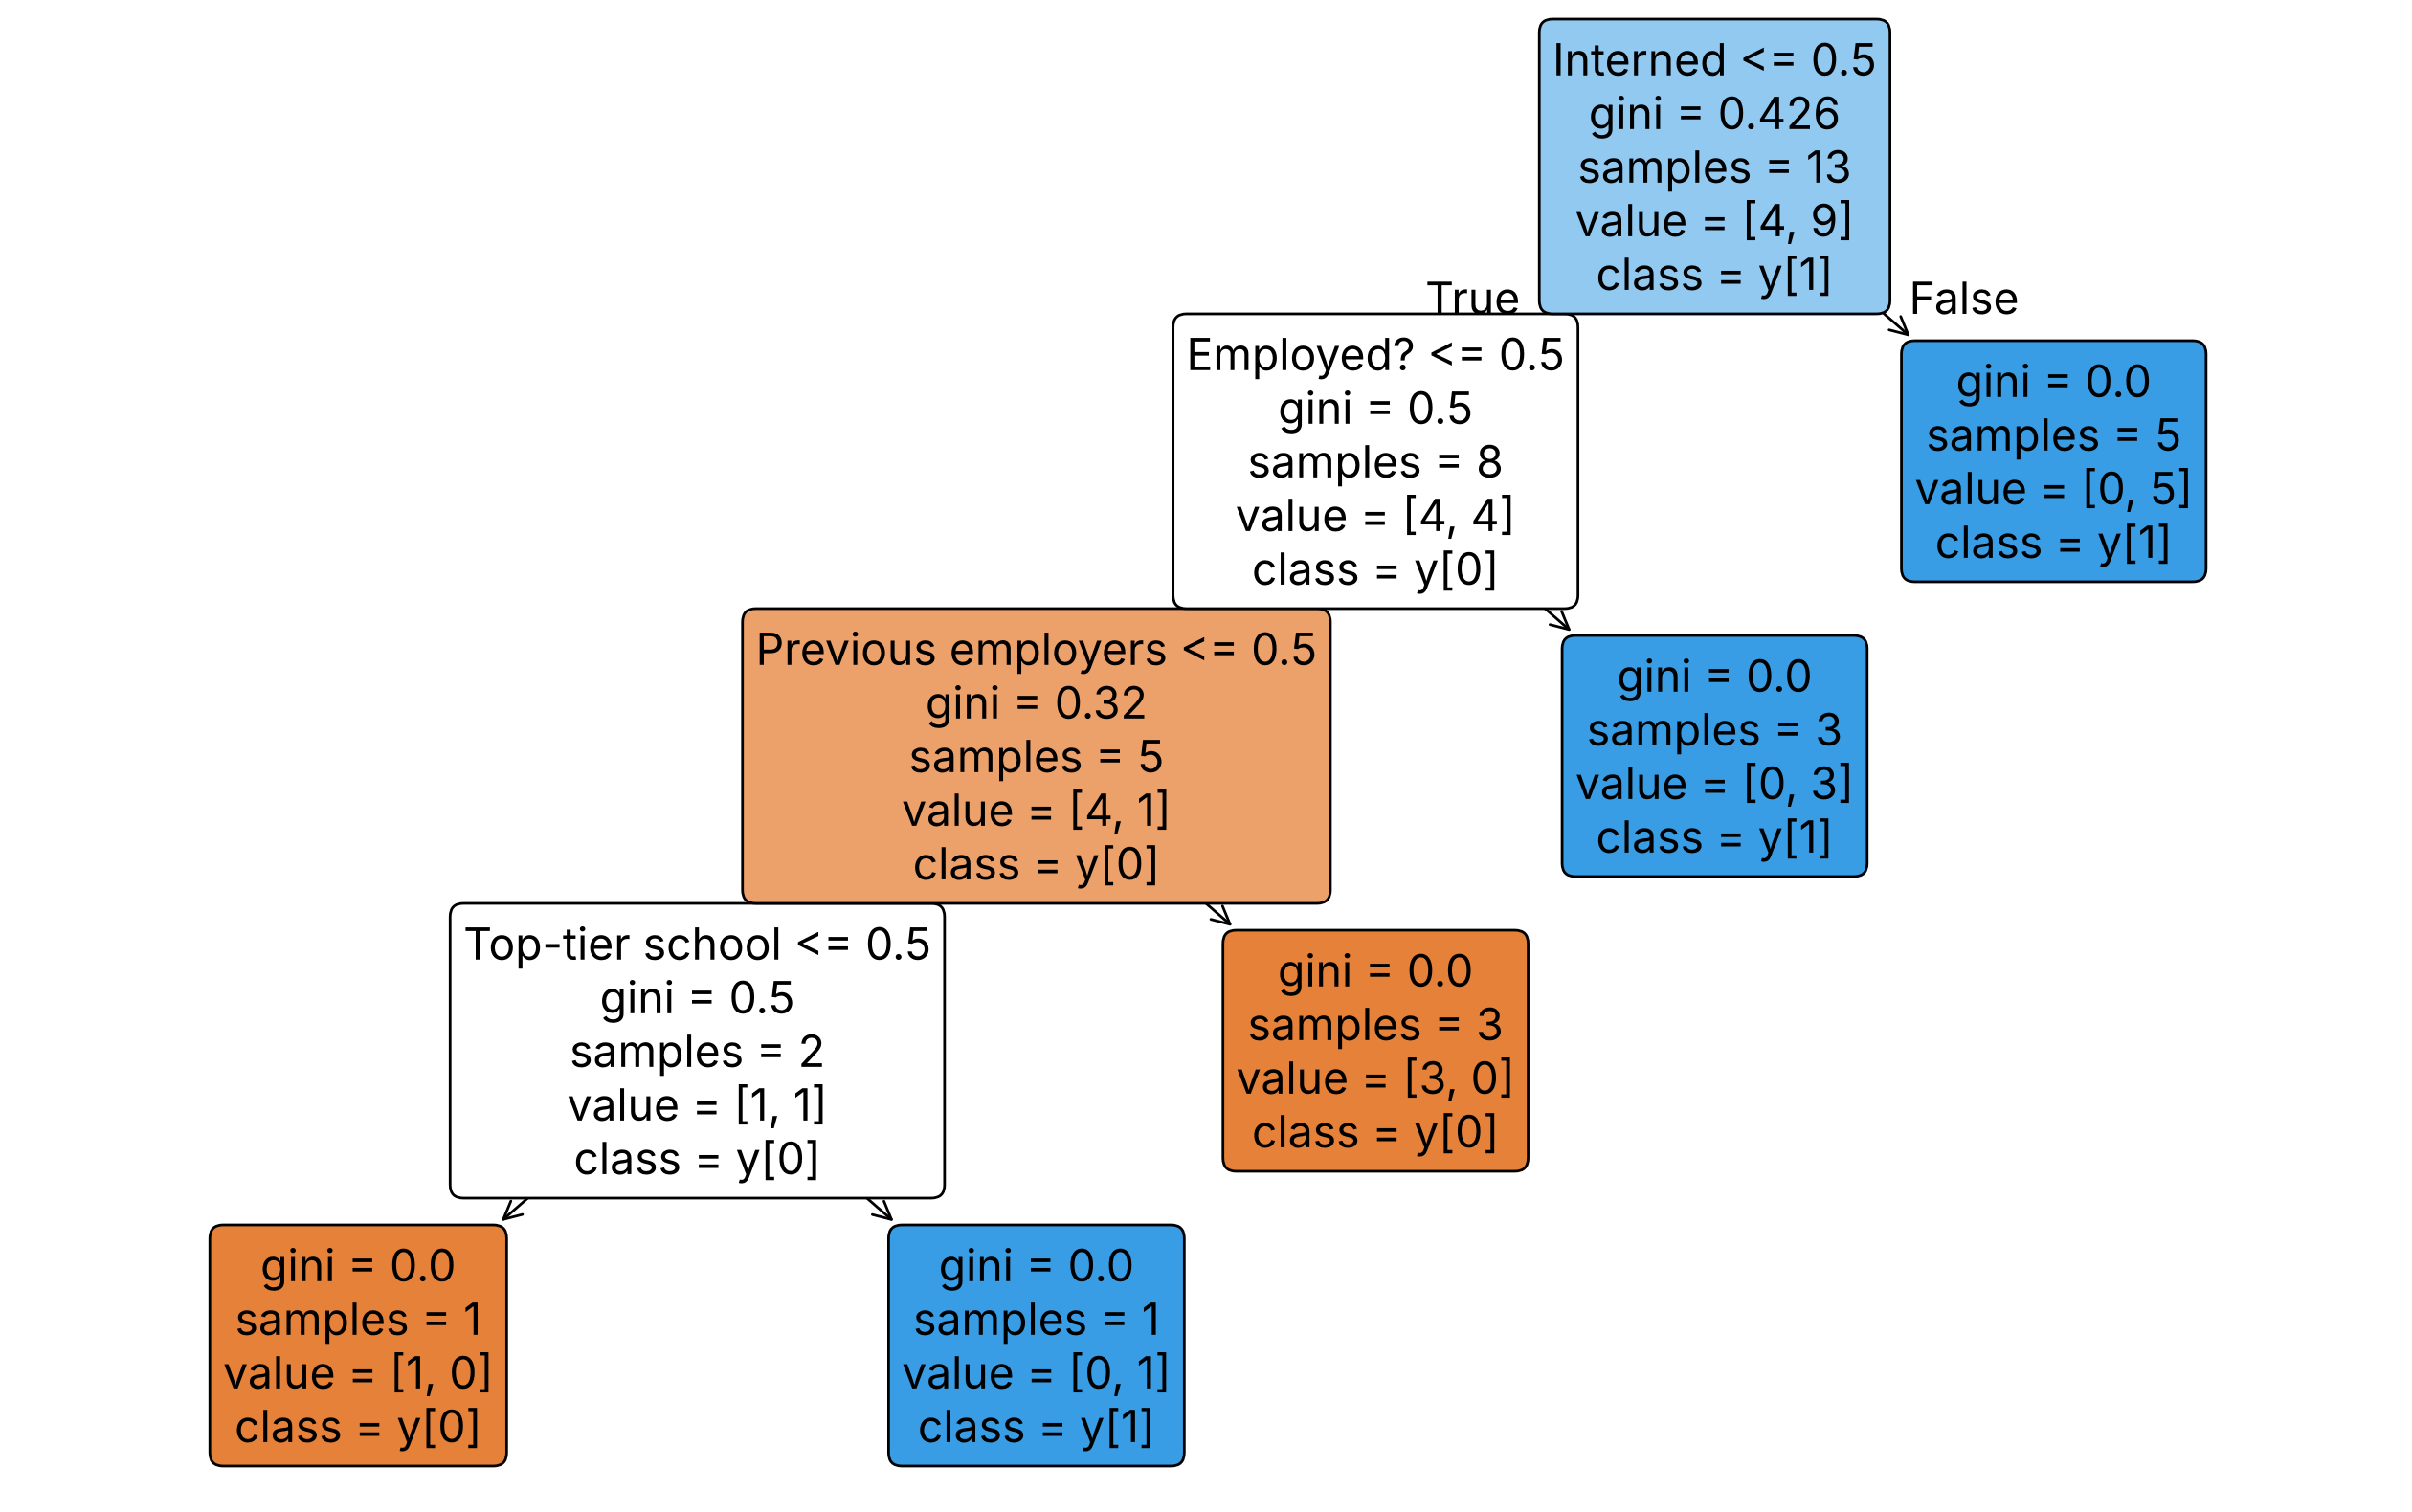

In [6]:
import matplotlib.pyplot as plt
from sklearn import tree

plt.figure(figsize=(16, 10))
tree.plot_tree(
    clf,
    feature_names=features,
    filled=True,
    rounded=True,
    class_names=True  # or replace with class names if needed
)
plt.show()


## Ensemble learning: using a random forest

We'll use a random forest of 10 decision trees to predict employment of specific candidate profiles:

In [7]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=10)
clf = clf.fit(X, y)

#Predict employment of an employed 10-year veteran
print (clf.predict([[10, 1, 4, 0, 0, 0]]))
#...and an unemployed 10-year veteran
print (clf.predict([[10, 0, 4, 0, 0, 0]]))

[1]
[0]


/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## Activity

1. **Gini vs. Entropy (Shannon) Criterion**  
   a. Modify the classifier using `criterion="entropy"` instead of `criterion="gini"`.  
   b. Retrain the tree and compare:  
      - the tree depth (`clf.get_depth()`),  
      - the number of leaves (`clf.get_n_leaves()`),  
      - and the test accuracy.  
   c. Do you notice a significant difference between Gini and Entropy? Which seems more suitable for this dataset?

2. **Effect of Tree Depth (Pruning)**  
   a. Train several trees with different `max_depth` values (e.g., 2, 3, 4, 5, None).  
   b. For each depth, compute the accuracy on both the training and test sets.  
   c. Optionally, plot a small chart (or table) of depth vs. accuracy.  
   d. Question: At what depth do you start to observe overfitting?

3. **Feature Importance**  
   a. Display `clf.feature_importances_` as a table (feature, importance).  
   b. Rank the features from most to least important.  
   c. Question: Are these results consistent with your intuition about the problem?

4. **Random Forest:** Compare the accuracy, result stability, and feature importance of Random Forest over a single decision tree. What can you say?

5. **Cross-Validation**  
   a. Use `cross_val_score` with `cv=5` to evaluate your decision tree on the full dataset.  
   b. Compare the mean cross-validation score with the accuracy from a simple train/test split.  
   c. Question: Is the performance stable across folds? What can you conclude about your model’s robustness?

6. Modify the data to create an alternate universe where the rules on who we should hire change according to you.

## Solution des activités

Le jeu de données ne contient que **13 observations** : les résultats sur un seul découpage train/test sont donc très bruités. On fixe `random_state` pour la reproductibilité et on complète par des répétitions / de la validation croisée.

In [8]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, ShuffleSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

df = pd.read_csv("PastHires.csv")
df["Hired"] = df["Hired"].map({"Y": 1, "N": 0})
for c in ["Employed?", "Top-tier school", "Interned"]:
    df[c] = df[c].map({"Y": 1, "N": 0})
df["Level of Education"] = df["Level of Education"].map({"BS": 0, "MS": 1, "PhD": 2})
features = list(df.columns[:6]); X = df[features]; y = df["Hired"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_tr.shape, X_te.shape)

(9, 6) (4, 6)


### 1. Gini vs Entropy

In [9]:
rows = []
for crit in ["gini", "entropy"]:
    t = DecisionTreeClassifier(criterion=crit, random_state=0).fit(X_tr, y_tr)
    # moyenne sur 200 découpages aléatoires pour lisser le bruit du petit échantillon
    accs = []
    for s in range(200):
        a, b, c, d = train_test_split(X, y, test_size=0.3, random_state=s, stratify=y)
        accs.append(DecisionTreeClassifier(criterion=crit, random_state=0).fit(a, c).score(b, d))
    rows.append({"critère": crit, "profondeur": t.get_depth(), "nb feuilles": t.get_n_leaves(),
                 "acc train": t.score(X_tr, y_tr), "acc test (split 42)": t.score(X_te, y_te),
                 "acc test moy. 200 splits": np.mean(accs)})
pd.DataFrame(rows).round(3)

,critère,profondeur,nb feuilles,acc train,acc test (split 42),acc test moy. 200 splits
0,gini,2,3,1.0,0.75,0.688
1,entropy,2,3,1.0,0.75,0.694


**Réponse**
- Avec les deux critères, l'arbre obtient **la même structure** : profondeur = 2, 3 feuilles, accuracy train = 1.0 et test = 0.75 (sur le split fixé, 4 échantillons de test seulement). Sur 200 découpages aléatoires : 0.688 (Gini) vs 0.694 (Entropy), soit une différence négligeable (~0.6 point).
- **Pas de différence significative** entre Gini et Entropy sur ce jeu de données (13 observations, 6 variables) : les deux mesures d'impureté sont très proches et choisissent presque toujours les mêmes séparations. Gini est légèrement plus rapide à calculer (pas de logarithme) ; Entropy tend à produire des arbres un peu plus équilibrés. On peut donc retenir **Gini** (par défaut, plus simple), l'écart n'étant pas significatif.

### 2. Effet de la profondeur (élagage)

,max_depth,profondeur réelle,train (split 42),test (split 42),train moy.,test moy.
0,1,1,0.667,0.75,0.764,0.538
1,2,2,1.000,0.75,0.927,0.719
2,3,2,1.000,0.75,0.953,0.705
3,4,2,1.000,0.75,0.997,0.688
4,5,2,1.000,0.75,1.000,0.688
5,None,2,1.000,0.75,1.000,0.688


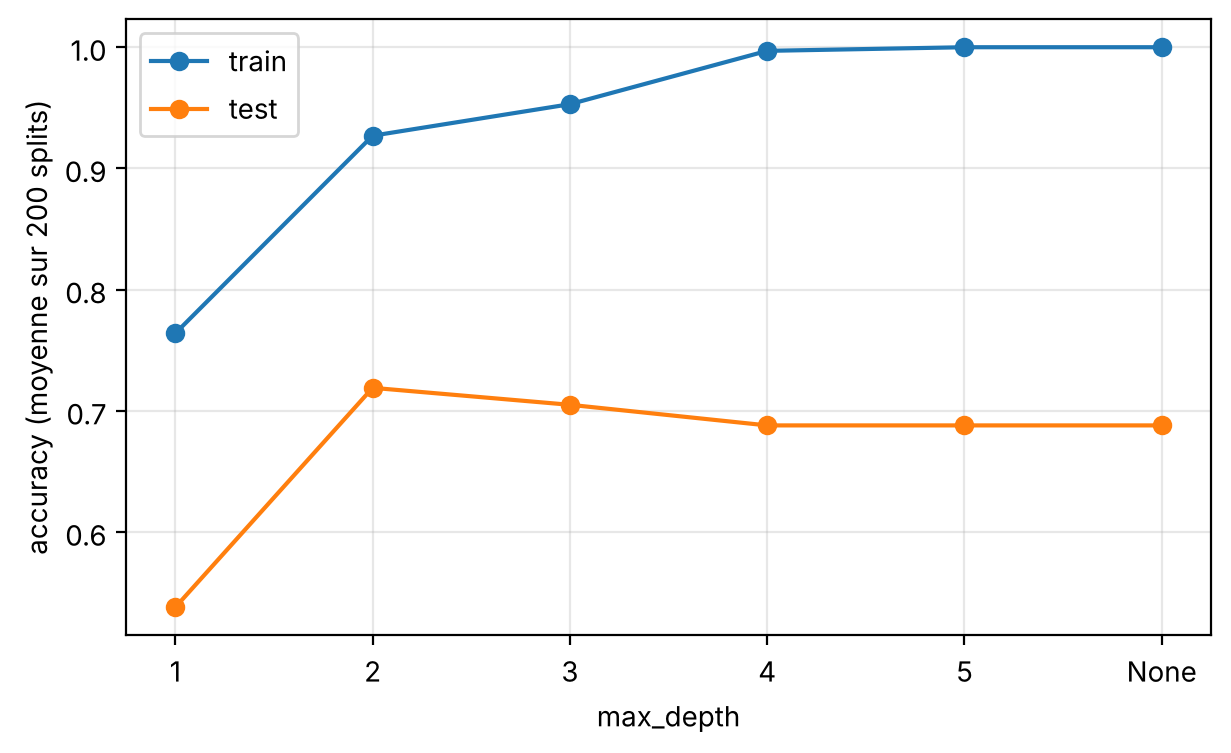

In [10]:
depths = [1, 2, 3, 4, 5, None]
rows = []
for dpt in depths:
    t = DecisionTreeClassifier(max_depth=dpt, random_state=0).fit(X_tr, y_tr)
    tr_a, te_a = [], []
    for s in range(200):
        a, b, c, d = train_test_split(X, y, test_size=0.3, random_state=s, stratify=y)
        m = DecisionTreeClassifier(max_depth=dpt, random_state=0).fit(a, c)
        tr_a.append(m.score(a, c)); te_a.append(m.score(b, d))
    rows.append({"max_depth": str(dpt), "profondeur réelle": t.get_depth(),
                 "train (split 42)": t.score(X_tr, y_tr), "test (split 42)": t.score(X_te, y_te),
                 "train moy.": np.mean(tr_a), "test moy.": np.mean(te_a)})
res = pd.DataFrame(rows).round(3); display(res)
plt.figure(figsize=(7, 4))
plt.plot(res["max_depth"], res["train moy."], marker="o", label="train")
plt.plot(res["max_depth"], res["test moy."], marker="o", label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy (moyenne sur 200 splits)"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Réponse**
- `max_depth=1` : sous-apprentissage (train moyen 0.76, test moyen 0.54).
- `max_depth=2` : **meilleur test moyen (0.719)** avec un train de 0.93.
- À partir de `max_depth ≥ 3`, le train monte vers 1.0 (0.95 → 1.0) alors que le test **baisse** (0.705 → 0.688) : début du **sur-apprentissage** dès la profondeur 3.
- Remarque : l'arbre non contraint (`None`) s'arrête naturellement à la profondeur 2 sur le split fixé (feuilles pures) ; sur les autres découpages il va plus profond, ce qui explique les moyennes qui continuent à diverger.
- Conclusion : une profondeur d'environ **2** est suffisante ; au-delà, l'arbre ne fait que mémoriser les 13 exemples.

### 3. Importance des variables

,feature,importance
rang,,
1,Interned,0.433
2,Employed?,0.278
3,Level of Education,0.181
4,Years Experience,0.108
5,Previous employers,0.000
6,Top-tier school,0.000


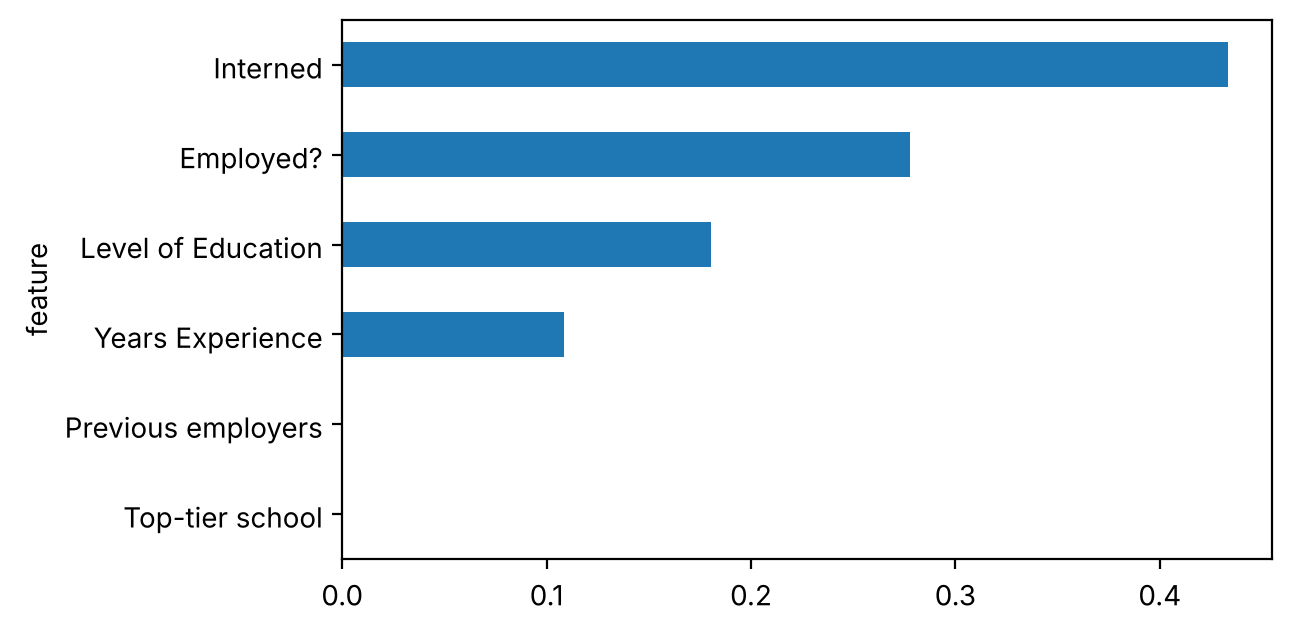

In [11]:
clf = DecisionTreeClassifier(random_state=0).fit(X, y)
imp = pd.DataFrame({"feature": features, "importance": clf.feature_importances_}).sort_values("importance", ascending=False).reset_index(drop=True)
imp.index += 1; imp.index.name = "rang"
display(imp.round(3))
imp.sort_values("importance").plot.barh(x="feature", y="importance", legend=False, figsize=(6, 3.5)); plt.show()

**Réponse**
Classement (arbre entraîné sur tout le jeu) : 1) **Interned** (0.43), 2) **Employed?** (0.28), 3) **Level of Education** (0.18), 4) **Years Experience** (0.11), 5-6) **Previous employers** et **Top-tier school** (0).
- Cohérent avec l'intuition : avoir fait un stage, être déjà employé et un niveau d'études élevé sont de bons signaux d'embauche ; *Top-tier school* n'est pas utilisée (les données ne l'exigent pas pour séparer les classes).
- Un peu surprenant : *Years Experience* et *Previous employers* comptent peu (ou pas) : dans ces 13 exemples, beaucoup d'expérience ne garantit pas l'embauche (ex. 20 ans d’expérience avec PhD non embauché, 7 ans et 6 employeurs non embauché). Attention : avec 13 observations, ces importances sont **instables** (cf. question 4).

### 4. Random Forest vs arbre unique

In [12]:
dt_acc, rf_acc = [], []
for s in range(100):
    a, b, c, d = train_test_split(X, y, test_size=0.3, random_state=s, stratify=y)
    dt_acc.append(DecisionTreeClassifier(random_state=s).fit(a, c).score(b, d))
    rf_acc.append(RandomForestClassifier(n_estimators=100, random_state=s).fit(a, c).score(b, d))
print(f"Arbre unique  : accuracy test moyenne = {np.mean(dt_acc):.3f}  (écart-type {np.std(dt_acc):.3f})")
print(f"Random Forest : accuracy test moyenne = {np.mean(rf_acc):.3f}  (écart-type {np.std(rf_acc):.3f})")

# stabilité des importances : on ré-entraîne 30 fois avec des graines différentes
imp_dt = np.array([DecisionTreeClassifier(random_state=s).fit(X, y).feature_importances_ for s in range(30)])
imp_rf = np.array([RandomForestClassifier(n_estimators=100, random_state=s).fit(X, y).feature_importances_ for s in range(30)])
cmp = pd.DataFrame({"arbre : moy.": imp_dt.mean(0), "arbre : écart-type": imp_dt.std(0),
                    "RF : moy.": imp_rf.mean(0), "RF : écart-type": imp_rf.std(0)}, index=features)
display(cmp.round(3))

Arbre unique  : accuracy test moyenne = 0.652  (écart-type 0.234)
Random Forest : accuracy test moyenne = 0.690  (écart-type 0.187)


,arbre : moy.,arbre : écart-type,RF : moy.,RF : écart-type
Years Experience,0.076,0.050,0.251,0.024
Employed?,0.381,0.073,0.168,0.019
Previous employers,0.032,0.050,0.209,0.021
Level of Education,0.096,0.090,0.107,0.023
Top-tier school,0.084,0.090,0.083,0.017
Interned,0.330,0.073,0.182,0.023


**Réponse**
- **Accuracy** : Random Forest 0.690 contre 0.652 pour l'arbre seul (moyenne sur 100 découpages) : meilleure, et **écart-type plus faible** (0.187 contre 0.234) → résultats plus **stables**.
- **Importances** : pour l'arbre, elles changent selon la graine (écarts-types ≈ 0.05–0.09) et se concentrent sur 2-3 variables (*Employed?* 0.38, *Interned* 0.33). La forêt est **plus lisse et plus stable** (écarts-types ≈ 0.02) et répartit l'importance sur toutes les variables, y compris *Years Experience* (0.25) et *Previous employers* (0.21) que l'arbre unique ignore presque.
- Conclusion : le Random Forest (bagging + sous-échantillonnage de variables) **réduit la variance** et donne une vision plus robuste de l'importance des variables, au prix d'une **perte d'interprétabilité** (on ne peut plus lire un arbre unique). Avec 13 observations, les gains restent modestes.

### 5. Validation croisée (cv=5)

In [13]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(DecisionTreeClassifier(random_state=0), X, y, cv=5)
print("Scores par fold :", scores.round(3))
print(f"Moyenne = {scores.mean():.3f}  |  écart-type = {scores.std():.3f}")
print(f"Accuracy sur le split simple (test_size=0.3, rs=42) : {DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr).score(X_te, y_te):.3f}")
scores_rf = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=0), X, y, cv=5)
print("\nRandom Forest cv=5 :", scores_rf.round(3), f"-> moyenne {scores_rf.mean():.3f}, écart-type {scores_rf.std():.3f}")

/usr/local/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Scores par fold : [1.    1.    0.333 1.    0.5  ]
Moyenne = 0.767  |  écart-type = 0.291
Accuracy sur le split simple (test_size=0.3, rs=42) : 0.750



Random Forest cv=5 : [0.667 1.    0.667 1.    0.   ] -> moyenne 0.667, écart-type 0.365


**Réponse**
- Scores par fold : `[1, 1, 0.33, 1, 0.5]`, moyenne = **0.767**, écart-type = **0.29**. Le split simple donnait 0.75 : les deux valeurs sont proches en moyenne, mais la validation croisée révèle la **forte variabilité** (de 0.33 à 1.0).
- La performance **n'est pas stable** entre les plis (chaque pli ne contient que 2-3 exemples, et une seule erreur change l'accuracy de 33-50 points ; sklearn avertit d'ailleurs que la classe minoritaire a moins de 5 membres).
- Conclusion : le modèle n'est pas démontré robuste ; la taille de l'échantillon (13) est le facteur limitant. Il faudrait plus de données avant de se fier à ces chiffres (même constat pour le Random Forest : CV moyenne 0.667, écart-type 0.37).

### 6. Univers alternatif : nouvelles règles d'embauche

**Nouvelle politique (inventée)** : l'entreprise valorise désormais surtout le *niveau d'études* et le *stage* ; l'expérience seule ne suffit plus.  
Règle : `Hired = 1` si (Interned = 1 **et** Level of Education ≥ 1 (MS/PhD)) **ou** (Top-tier school = 1 **et** Years Experience ≤ 5), sinon 0.

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
0,10,1,4,0,0,0,0
1,0,0,0,0,1,1,1
2,7,0,6,0,0,0,0
3,2,1,1,1,1,0,1
4,20,0,2,2,1,0,0
5,0,0,0,2,1,1,1
6,5,1,2,1,0,1,1
7,3,0,1,0,0,1,0
8,15,1,5,0,0,0,0
9,0,0,0,0,0,0,0


Répartition : {0: 7, 1: 6}


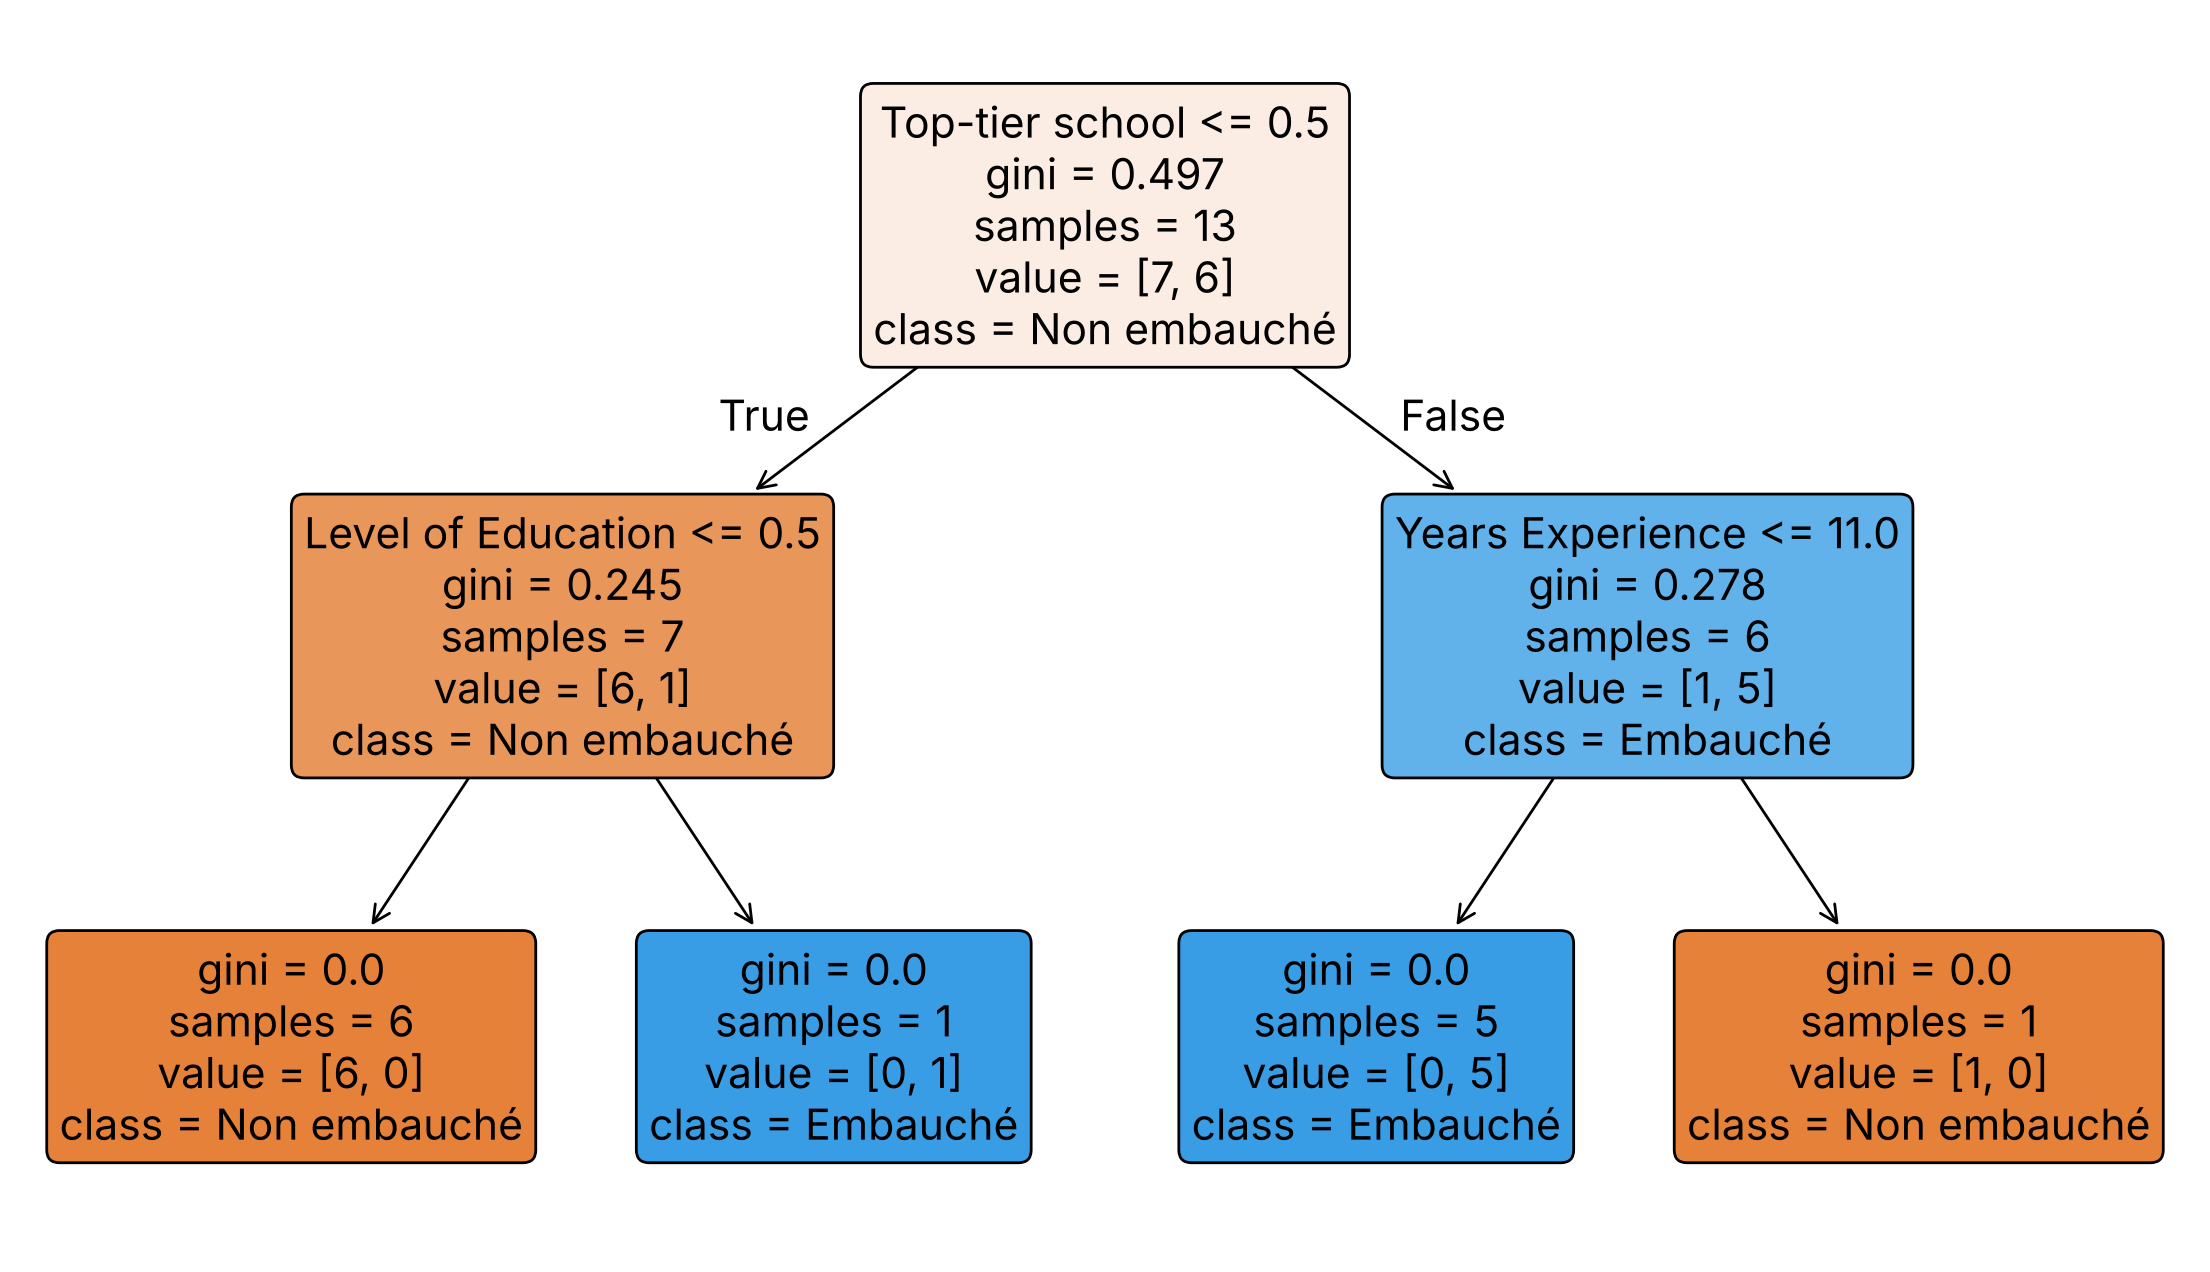

,importance
Top-tier school,0.477
Level of Education,0.265
Years Experience,0.258
Employed?,0.000
Previous employers,0.000
Interned,0.000


,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,prédiction (arbre),prédiction (RF)
0,10,1,4,0,0,0,0,0
1,2,0,1,2,1,1,1,1
2,1,0,0,1,0,1,1,1
3,8,1,3,0,0,0,0,0


In [14]:
alt = df.copy()
alt["Hired"] = (((alt["Interned"] == 1) & (alt["Level of Education"] >= 1)) |
                ((alt["Top-tier school"] == 1) & (alt["Years Experience"] <= 5))).astype(int)
display(alt)
print("Répartition :", alt["Hired"].value_counts().to_dict())

t_alt = DecisionTreeClassifier(random_state=0).fit(alt[features], alt["Hired"])
plt.figure(figsize=(14, 8))
tree.plot_tree(t_alt, feature_names=features, class_names=["Non embauché", "Embauché"], filled=True, rounded=True)
plt.show()
display(pd.Series(t_alt.feature_importances_, index=features).sort_values(ascending=False).round(3).to_frame("importance"))

rf_alt = RandomForestClassifier(n_estimators=100, random_state=0).fit(alt[features], alt["Hired"])
cands = pd.DataFrame([[10,1,4,0,0,0],[2,0,1,2,1,1],[1,0,0,1,0,1],[8,1,3,0,0,0]], columns=features)
cands["prédiction (arbre)"] = t_alt.predict(cands[features]); cands["prédiction (RF)"] = rf_alt.predict(cands[features])
cands

**Analyse**
- La nouvelle règle (stage + master/doctorat, ou grande école + peu d'expérience) donne 6 embauchés / 7 non embauchés.
- L'arbre appris s'adapte : les variables importantes deviennent **Top-tier school** (0.48), **Level of Education** (0.27) et **Years Experience** (0.26), alors que *Employed?* et *Previous employers* passent à 0 : l'arbre reflète bien le changement de politique.
- Il n'utilise pas *Interned*, bien que la règle l'implique : avec 13 exemples, d'autres variables suffisent à séparer les données (un arbre apprend un raccourci cohérent avec les données, pas forcément la vraie règle). Les prédictions sur 4 candidats fictifs sont cohérentes avec la règle (le vétéran de 10 ans sans master/stage n'est plus embauché).
- Leçon : le modèle est le reflet des **données d'entraînement** ; changer les critères d'embauche (et donc les étiquettes) change complètement les variables jugées importantes.